Device: cuda
GPU: Tesla T4
Using Colab cache for faster access to the 'pistachio-image-dataset' dataset.

Path to dataset files:
/kaggle/input/pistachio-image-dataset

Searching dataset folders...
/kaggle/input/pistachio-image-dataset
/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset
/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_16_Features_Dataset
/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset
/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_28_Features_Dataset

Dataset path:
/kaggle/input/pistachio-image-dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset

Classes:
['Kirmizi_Pistachio', 'Siirt_Pistachio']

Number of classes:
2

Total images:
2148

Images per class:
Kirmizi_Pistachio : 1232
Siirt_Pistachio : 916

Training images: 1718
Testing images: 430

DataLoaders created successfully.

Number of classes: 2

Loading AlexNet...
AlexNet loaded successfully.

Loading VGG16...
VGG16 

,Model,Training Accuracy (%),Test Accuracy (%),Test Loss,Training Time (min)
1,VGG16,99.01,98.14,0.1088,2.83
2,ResNet50,95.87,97.21,0.1331,2.19
0,AlexNet,93.36,94.19,0.1930,1.98
3,EfficientNetB0,92.32,93.72,0.1496,1.96


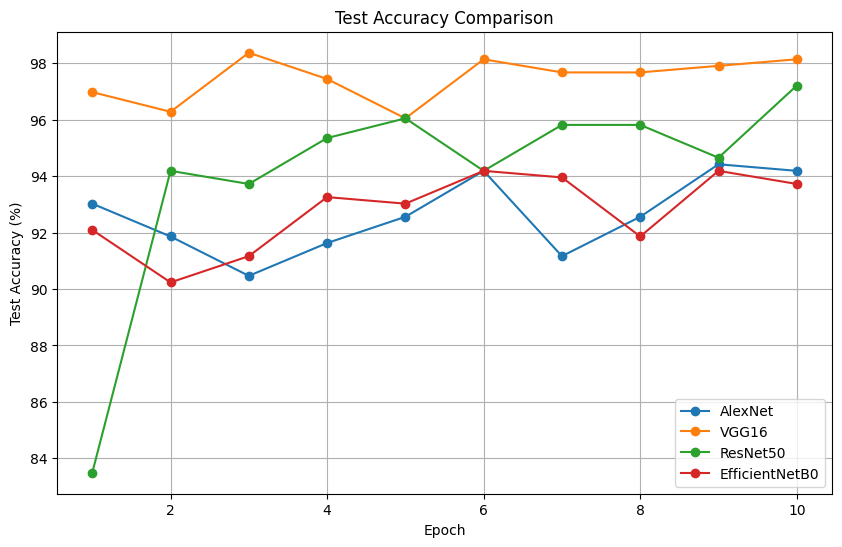

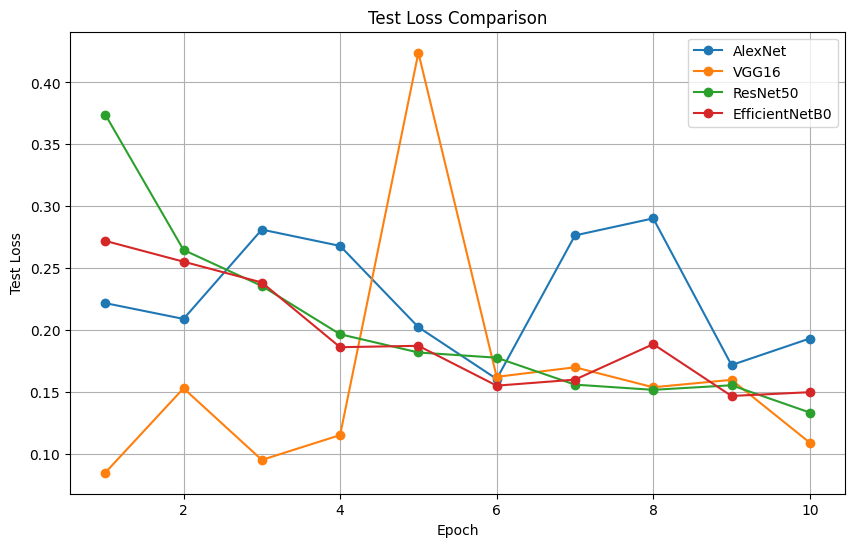

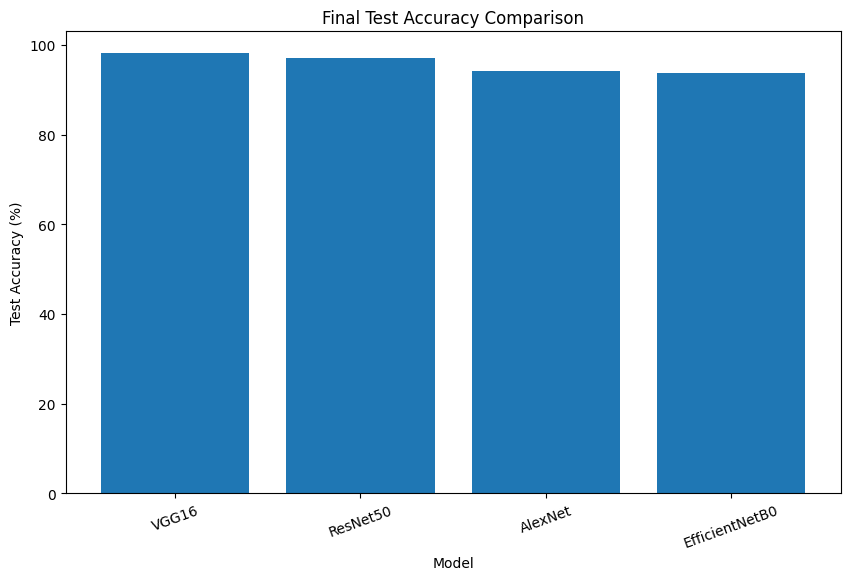

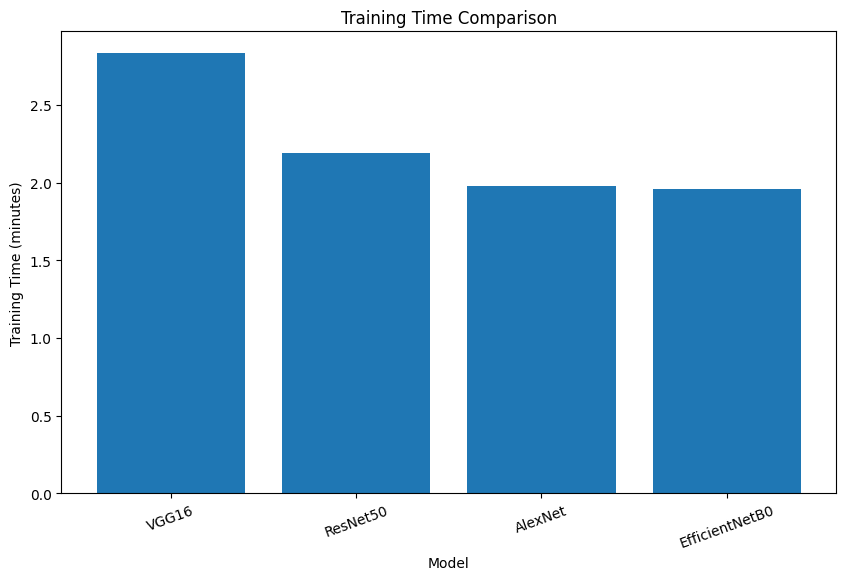



BEST MODEL
Model: VGG16
Test Accuracy: 98.14 %
Saved: alexnet_pistachio.pth
Saved: vgg16_pistachio.pth
Saved: resnet50_pistachio.pth
Saved: efficientnetb0_pistachio.pth


In [ ]:
# ============================================================
# 1. INSTALL KAGGLEHUB
# ============================================================

!pip install -q kagglehub


# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split


# ============================================================
# 3. CHECK GPU
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not available.")


# ============================================================
# 4. DOWNLOAD PISTACHIO DATASET USING KAGGLEHUB
# ============================================================

import kagglehub

path = kagglehub.dataset_download(
    "muratkokludataset/pistachio-image-dataset"
)

print("\nPath to dataset files:")
print(path)


# ============================================================
# 5. FIND DATASET FOLDER AUTOMATICALLY
# ============================================================

print("\nSearching dataset folders...")

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    if level <= 2:
        print(root)


# ============================================================
# 6. FIND IMAGE FOLDER AUTOMATICALLY
# ============================================================

dataset_path = None

# Look for a folder that contains class subfolders
for root, dirs, files in os.walk(path):

    if len(dirs) >= 2:

        # Check whether subfolders contain image files
        valid_class_folders = 0

        for d in dirs:
            folder = os.path.join(root, d)

            try:
                files_inside = os.listdir(folder)

                image_count = sum(
                    1
                    for f in files_inside
                    if f.lower().endswith(
                        (".jpg", ".jpeg", ".png", ".bmp")
                    )
                )

                if image_count > 0:
                    valid_class_folders += 1

            except:
                pass

        if valid_class_folders >= 2:
            dataset_path = root
            break


print("\nDataset path:")
print(dataset_path)

if dataset_path is None:
    raise FileNotFoundError(
        "Could not automatically find the image dataset folder."
    )


# ============================================================
# 7. IMAGE TRANSFORMATION
# ============================================================

transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 8. LOAD DATASET
# ============================================================

dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=transform
)

print("\nClasses:")
print(dataset.classes)

print("\nNumber of classes:")
print(len(dataset.classes))

print("\nTotal images:")
print(len(dataset))


# ============================================================
# 9. SHOW NUMBER OF IMAGES PER CLASS
# ============================================================

print("\nImages per class:")

for class_name in dataset.classes:

    class_id = dataset.class_to_idx[class_name]

    count = sum(
        1
        for _, label in dataset.samples
        if label == class_id
    )

    print(
        class_name,
        ":",
        count
    )


# ============================================================
# 10. TRAIN / TEST SPLIT
# ============================================================

train_size = int(
    0.8 * len(dataset)
)

test_size = (
    len(dataset) - train_size
)

train_dataset, test_dataset = random_split(
    dataset,
    [train_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print("\nTraining images:", len(train_dataset))
print("Testing images:", len(test_dataset))


# ============================================================
# 11. DATALOADERS
# ============================================================

BATCH_SIZE = 16

pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=pin_memory
)

print("\nDataLoaders created successfully.")


# ============================================================
# 12. NUMBER OF CLASSES
# ============================================================

NUM_CLASSES = len(
    dataset.classes
)

print(
    "\nNumber of classes:",
    NUM_CLASSES
)


# ============================================================
# 13. LOAD ALEXNET
# ============================================================

print("\nLoading AlexNet...")

alexnet = models.alexnet(
    weights=models.AlexNet_Weights.DEFAULT
)

# Freeze pretrained feature layers
for param in alexnet.features.parameters():
    param.requires_grad = False

# Replace final layer
alexnet.classifier[6] = nn.Linear(
    alexnet.classifier[6].in_features,
    NUM_CLASSES
)

alexnet = alexnet.to(device)

print("AlexNet loaded successfully.")


# ============================================================
# 14. LOAD VGG16
# ============================================================

print("\nLoading VGG16...")

vgg16 = models.vgg16(
    weights=models.VGG16_Weights.DEFAULT
)

# Freeze feature layers
for param in vgg16.features.parameters():
    param.requires_grad = False

# Replace final layer
vgg16.classifier[6] = nn.Linear(
    vgg16.classifier[6].in_features,
    NUM_CLASSES
)

vgg16 = vgg16.to(device)

print("VGG16 loaded successfully.")


# ============================================================
# 15. LOAD RESNET50
# ============================================================

print("\nLoading ResNet50...")

resnet50 = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Freeze all pretrained layers
for param in resnet50.parameters():
    param.requires_grad = False

# Replace final layer
resnet50.fc = nn.Linear(
    resnet50.fc.in_features,
    NUM_CLASSES
)

resnet50 = resnet50.to(device)

print("ResNet50 loaded successfully.")


# ============================================================
# 16. LOAD EFFICIENTNETB0
# ============================================================

print("\nLoading EfficientNetB0...")

efficientnet = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

# Freeze feature layers
for param in efficientnet.features.parameters():
    param.requires_grad = False

# Replace final layer
efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    NUM_CLASSES
)

efficientnet = efficientnet.to(device)

print("EfficientNetB0 loaded successfully.")


# ============================================================
# 17. STORE ALL MODELS
# ============================================================

models_dict = {

    "AlexNet": alexnet,

    "VGG16": vgg16,

    "ResNet50": resnet50,

    "EfficientNetB0": efficientnet

}


# ============================================================
# 18. TRAINING FUNCTION
# ============================================================

def train_model(
    model,
    model_name,
    epochs=3
):

    print("\n")
    print("=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    criterion = nn.CrossEntropyLoss()

    # Only train unfrozen parameters
    optimizer = optim.Adam(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=0.001
    )

    train_losses = []
    train_accuracies = []

    test_losses = []
    test_accuracies = []

    start_time = time.time()

    for epoch in range(epochs):

        # ====================================================
        # TRAINING
        # ====================================================

        model.train()

        running_loss = 0.0

        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

        train_loss = (
            running_loss /
            len(train_loader)
        )

        train_accuracy = (
            100 * correct / total
        )


        # ====================================================
        # TESTING
        # ====================================================

        model.eval()

        test_loss = 0.0

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in test_loader:

                images = images.to(
                    device,
                    non_blocking=True
                )

                labels = labels.to(
                    device,
                    non_blocking=True
                )

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                test_loss += loss.item()

                _, predicted = torch.max(
                    outputs,
                    1
                )

                total += labels.size(0)

                correct += (
                    predicted == labels
                ).sum().item()

        test_loss = (
            test_loss /
            len(test_loader)
        )

        test_accuracy = (
            100 * correct / total
        )


        # ====================================================
        # SAVE RESULTS
        # ====================================================

        train_losses.append(
            train_loss
        )

        train_accuracies.append(
            train_accuracy
        )

        test_losses.append(
            test_loss
        )

        test_accuracies.append(
            test_accuracy
        )


        # ====================================================
        # PRINT RESULTS
        # ====================================================

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_accuracy:.2f}% "
            f"| Test Loss: {test_loss:.4f} "
            f"| Test Acc: {test_accuracy:.2f}%"
        )


    training_time = (
        time.time() - start_time
    )

    print(
        f"\n{model_name} completed in "
        f"{training_time / 60:.2f} minutes."
    )


    history = {

        "train_loss": train_losses,

        "train_accuracy":
            train_accuracies,

        "test_loss":
            test_losses,

        "test_accuracy":
            test_accuracies

    }

    return (
        model,
        history,
        training_time
    )


# ============================================================
# 19. TRAIN ALL FOUR MODELS
# ============================================================

EPOCHS = 10

results = {}

trained_models = {}

for name, model in models_dict.items():

    trained_model, history, training_time = train_model(

        model,

        name,

        epochs=EPOCHS

    )

    trained_models[name] = (
        trained_model
    )

    results[name] = {

        "history": history,

        "training_time":
            training_time

    }


# ============================================================
# 20. CREATE COMPARISON TABLE
# ============================================================

comparison = []

for name, result in results.items():

    history = result["history"]

    comparison.append({

        "Model":
            name,

        "Training Accuracy (%)":
            round(
                history[
                    "train_accuracy"
                ][-1],
                2
            ),

        "Test Accuracy (%)":
            round(
                history[
                    "test_accuracy"
                ][-1],
                2
            ),

        "Test Loss":
            round(
                history[
                    "test_loss"
                ][-1],
                4
            ),

        "Training Time (min)":
            round(
                result[
                    "training_time"
                ] / 60,
                2
            )

    })


comparison_df = pd.DataFrame(
    comparison
)

comparison_df = comparison_df.sort_values(
    by="Test Accuracy (%)",
    ascending=False
)

print("\n")
print("=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)

display(comparison_df)


# ============================================================
# 21. TEST ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for name, result in results.items():

    plt.plot(

        range(
            1,
            EPOCHS + 1
        ),

        result[
            "history"
        ][
            "test_accuracy"
        ],

        marker="o",

        label=name
    )

plt.xlabel("Epoch")

plt.ylabel(
    "Test Accuracy (%)"
)

plt.title(
    "Test Accuracy Comparison"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 22. TEST LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for name, result in results.items():

    plt.plot(

        range(
            1,
            EPOCHS + 1
        ),

        result[
            "history"
        ][
            "test_loss"
        ],

        marker="o",

        label=name
    )

plt.xlabel("Epoch")

plt.ylabel(
    "Test Loss"
)

plt.title(
    "Test Loss Comparison"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 23. FINAL ACCURACY COMPARISON
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.bar(

    comparison_df[
        "Model"
    ],

    comparison_df[
        "Test Accuracy (%)"
    ]

)

plt.xlabel("Model")

plt.ylabel(
    "Test Accuracy (%)"
)

plt.title(
    "Final Test Accuracy Comparison"
)

plt.xticks(
    rotation=20
)

plt.show()


# ============================================================
# 24. TRAINING TIME COMPARISON
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.bar(

    comparison_df[
        "Model"
    ],

    comparison_df[
        "Training Time (min)"
    ]

)

plt.xlabel("Model")

plt.ylabel(
    "Training Time (minutes)"
)

plt.title(
    "Training Time Comparison"
)

plt.xticks(
    rotation=20
)

plt.show()


# ============================================================
# 25. FIND BEST MODEL
# ============================================================

best_model = comparison_df.iloc[0]

print("\n")
print("=" * 50)
print("BEST MODEL")
print("=" * 50)

print(
    "Model:",
    best_model["Model"]
)

print(
    "Test Accuracy:",
    best_model[
        "Test Accuracy (%)"
    ],
    "%"
)


# ============================================================
# 26. SAVE MODELS
# ============================================================

for name, model in trained_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        + "_pistachio.pth"
    )

    torch.save(
        model.state_dict(),
        filename
    )

    print(
        "Saved:",
        filename
    )


# ============================================================
# 27. SINGLE IMAGE PREDICTION FUNCTION
# ============================================================

def predict_image(
    image_path,
    model,
    class_names
):

    model.eval()

    image = Image.open(
        image_path
    ).convert("RGB")

    image_tensor = transform(
        image
    ).unsqueeze(0)

    image_tensor = image_tensor.to(
        device
    )

    with torch.no_grad():

        output = model(
            image_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        confidence, predicted = torch.max(
            probabilities,
            1
        )

    predicted_class = class_names[
        predicted.item()
    ]

    print(
        "Predicted Class:",
        predicted_class
    )

    print(
        "Confidence:",
        f"{confidence.item() * 100:.2f}%"
    )

    plt.figure(
        figsize=(5, 5)
    )

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"{predicted_class} "
        f"({confidence.item() * 100:.2f}%)"
    )

    plt.show()